# Phase 2 & 4: Segmentation (U-Net)

A U-Net with a pretrained ResNet34 encoder draws the outline (mask) of every lesion.

One setting, `MULTI_TASK`, switches between the two phases:

| `MULTI_TASK` | Phase | Model outputs | Saved to |
| :----------: | ----- | ------------- | -------- |
| `False` | Phase 2 | Lesion mask | `outputs/unet/` |
| `True` | Phase 4 | Lesion mask **and** normal / benign / malignant | `outputs/unet_multitask/` |

Run it once with each setting to compare them. Each run saves to its own folder.

**Input:** `data/manifest.csv` (created by `00_clean_data.ipynb`)

**Output** (everything the Streamlit app needs):

| File | What it contains |
| ---- | ---------------- |
| `model.pt` | Trained model weights (best epoch) |
| `config.json` | Architecture, image size, normalisation, threshold and training settings |
| `history.csv` | Loss, Dice and accuracy for every epoch |
| `metrics.json` | Test results |
| `test_predictions.csv` | Dice, IoU and lesion area for every test image (+ class probabilities if multi-task) |
| `masks/` | Predicted mask for every test image, at the original image size (used by `04_measure`) |
| `training_curves.png`, `dice_distribution.png`, `prediction_examples.png`, `worst_predictions.png` | Result plots |
| `confusion_matrix.png` | Test confusion matrix (multi-task only) |

**Before the first run:** install the U-Net library with `.env/bin/pip install segmentation-models-pytorch`. The pretrained encoder weights download automatically the first time (about 85 MB).

## 1. Imports

In [2]:
import json
import random
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import segmentation_models_pytorch as smp
from PIL import Image, ImageOps
from torch.utils.data import Dataset, DataLoader
from torchvision import tv_tensors
from torchvision.transforms import v2
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, roc_auc_score

/Users/prajwalnerkar/Prajwal/Projects/Breast Cancer Detection/.env/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 2. Settings

In [3]:
DATA_DIR = Path('data')

MULTI_TASK = True    # False = Phase 2 (mask only), True = Phase 4 (mask + normal / benign / malignant)

OUTPUT_DIR = Path('outputs/unet_multitask' if MULTI_TASK else 'outputs/unet')
MASK_DIR = OUTPUT_DIR / 'masks'                 # predicted test masks go here
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

CLASSES = ['normal', 'benign', 'malignant']     # class numbers 0, 1, 2
ENCODER = 'resnet34'          # pretrained backbone of the U-Net
IMAGE_SIZE = 256              # every scan is padded and resized to 256 x 256
BATCH_SIZE = 8
EPOCHS = 40                   # maximum; training can stop earlier
LEARNING_RATE = 1e-4
PATIENCE = 8                  # stop if validation loss hasn't improved for this many epochs
CLASS_LOSS_WEIGHT = 0.5       # how much the classification loss counts compared to the mask loss
MASK_THRESHOLD = 0.5          # pixels with lesion probability above this are part of the mask
MIN_LESION_PIXELS = 50        # same as 00_clean_data: smaller regions are noise
RANDOM_STATE = 42

IMAGENET_MEAN = [0.485, 0.456, 0.406]           # the pretrained encoder expects images normalised this way
IMAGENET_STD = [0.229, 0.224, 0.225]

# Same results every run
random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)

# Use the Apple GPU (mps) if available, otherwise the CPU
device = torch.device('mps' if torch.backends.mps.is_available() else 'cpu')
print('Using device:', device, '| Multi-task:', MULTI_TASK, '| Saving to:', OUTPUT_DIR)

Using device: mps | Multi-task: True | Saving to: outputs/unet_multitask


## 3. Load the manifest

In [4]:
df = pd.read_csv(DATA_DIR / 'manifest.csv')
df['target'] = df['label'].map(CLASSES.index)     # class name -> class number

train_df = df[df['split'] == 'train'].reset_index(drop=True)
val_df = df[df['split'] == 'val'].reset_index(drop=True)
test_df = df[df['split'] == 'test'].reset_index(drop=True)

print(f'Train: {len(train_df)}  |  Val: {len(val_df)}  |  Test: {len(test_df)}')

Train: 485  |  Val: 104  |  Test: 104


## 4. Images, masks and helper functions

Image and mask go through the **same** padding and resizing, so they stay perfectly aligned:
- **Image:** grayscale, then black borders to make it square, then resize to 256 x 256 (smooth resizing).
- **Mask:** all of the image's masks merged into one, then the same borders and resize, using *nearest-neighbour* resizing so pixels stay exactly 0 or 1.

`unpad_mask` does the reverse: it cuts the borders off a predicted 256 x 256 mask and resizes it back to the original image size, so lesions can be measured in real image pixels.

In [5]:
def pad_to_square(image, is_mask=False, size=IMAGE_SIZE):
    """Fit an image into size x size with black borders (no stretching)."""
    method = Image.NEAREST if is_mask else Image.BICUBIC      # nearest keeps mask pixels exactly 0 or 255
    return ImageOps.pad(image, (size, size), method=method, color=0)


def load_mask(mask_paths):
    """Merge all masks of an image into one PIL image (255 = lesion, 0 = background)."""
    masks = [np.array(Image.open(DATA_DIR / p).convert('L')) > 127 for p in mask_paths.split(';')]
    return Image.fromarray(np.any(masks, axis=0).astype(np.uint8) * 255)


def unpad_mask(mask, width, height, size=IMAGE_SIZE):
    """Undo pad_to_square: cut off the borders and resize a True/False mask back to width x height."""
    scale = size / max(width, height)
    new_width, new_height = round(width * scale), round(height * scale)              # image size inside the square
    left, top = round((size - new_width) / 2), round((size - new_height) / 2)        # where the image starts
    cropped = mask[top:top + new_height, left:left + new_width]
    resized = Image.fromarray(cropped.astype(np.uint8) * 255).resize((width, height), Image.NEAREST)
    return np.array(resized) > 127


def dice_score(pred, truth):
    """Overlap of two True/False masks: 1 = identical, 0 = no overlap."""
    total = pred.sum() + truth.sum()
    return 1.0 if total == 0 else float(2 * (pred & truth).sum() / total)


def iou_score(pred, truth):
    """Intersection over union of two True/False masks: 1 = identical, 0 = no overlap."""
    union = (pred | truth).sum()
    return 1.0 if union == 0 else float((pred & truth).sum() / union)

In [6]:
# Check: padding a real mask and undoing it should give back (almost) the same mask
row = df[df['label'] == 'malignant'].iloc[0]
original = np.array(load_mask(row['mask_paths'])) > 127
padded = np.array(pad_to_square(load_mask(row['mask_paths']), is_mask=True)) > 127
round_trip = unpad_mask(padded, row['width'], row['height'])

print(f'Dice after pad + unpad: {dice_score(round_trip, original):.3f}  (should be close to 1; '
      f'a little below is normal because the mask was shrunk to 256 x 256)')

Dice after pad + unpad: 0.996  (should be close to 1; a little below is normal because the mask was shrunk to 256 x 256)


### Augmentation and dataset

Training images get small random flips, rotations, shifts and zooms. Each change is applied to the image **and** its mask together, so the outline still matches. Brightness and contrast changes only affect the image. There are no vertical flips, because the skin is always at the top.

In [7]:
train_augment = v2.Compose([
    v2.RandomHorizontalFlip(),                                              # left-right flip only
    v2.RandomAffine(degrees=10, translate=(0.05, 0.05), scale=(0.9, 1.1)),  # small rotation, shift, zoom
    v2.ColorJitter(brightness=0.2, contrast=0.2),                           # image only, the mask is untouched
])

MEAN = torch.tensor(IMAGENET_MEAN).view(3, 1, 1)
STD = torch.tensor(IMAGENET_STD).view(3, 1, 1)


def to_model_input(image):
    """1-channel uint8 image tensor (1, H, W) -> normalised 3-channel float tensor (3, H, W)."""
    x = torch.as_tensor(image).float().div(255).repeat(3, 1, 1)   # 0..255 -> 0..1, then copy to 3 channels
    return (x - MEAN) / STD


class ScanMaskDataset(Dataset):
    """Gives (image tensor, mask tensor, class number) for each row of the manifest."""

    def __init__(self, frame, augment=None):
        self.frame = frame
        self.augment = augment

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, i):
        row = self.frame.iloc[i]
        image = pad_to_square(Image.open(DATA_DIR / row['image_path']).convert('L'))
        mask = pad_to_square(load_mask(row['mask_paths']), is_mask=True)

        image = tv_tensors.Image(torch.from_numpy(np.array(image)).unsqueeze(0))                   # (1, H, W)
        mask = tv_tensors.Mask(torch.from_numpy(np.array(mask) > 127).unsqueeze(0).to(torch.uint8))
        if self.augment:
            image, mask = self.augment(image, mask)       # same random change for image and mask

        return to_model_input(image), torch.as_tensor(mask).float(), row['target']


train_loader = DataLoader(ScanMaskDataset(train_df, train_augment), batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(ScanMaskDataset(val_df), batch_size=BATCH_SIZE)
test_loader = DataLoader(ScanMaskDataset(test_df), batch_size=BATCH_SIZE)    # keeps test_df order

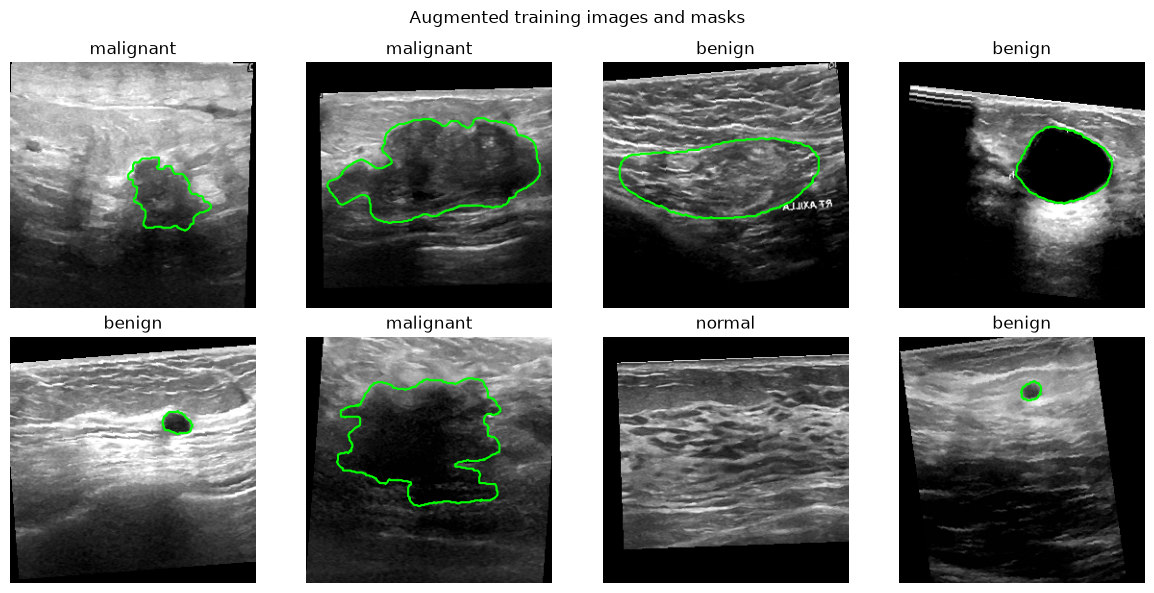

In [8]:
# Look at one batch of augmented training images with their masks (green outline)
images, masks, targets = next(iter(train_loader))

fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for ax, image, mask, target in zip(axes.flat, images, masks, targets):
    ax.imshow((image[0] * IMAGENET_STD[0] + IMAGENET_MEAN[0]).numpy(), cmap='gray')   # undo normalisation
    if mask.any():
        ax.contour(mask[0].numpy(), levels=[0.5], colors='lime', linewidths=1.5)
    ax.set_title(CLASSES[target])
    ax.axis('off')
plt.suptitle('Augmented training images and masks')
plt.tight_layout()
plt.show()

## 5. Model and loss

**U-Net:** the *encoder* (a ResNet34 pretrained on ImageNet) shrinks the image step by step into features. The *decoder* grows those features back to full size to draw the mask. *Skip connections* pass details from each encoder step to the decoder, which keeps the edges sharp.

With `MULTI_TASK = True`, a small **classification head** also reads the encoder's deepest features and predicts normal / benign / malignant.

**Mask loss = Dice loss + binary cross-entropy:**
- **Dice loss** rewards overlap between the predicted and true mask. It works well even when the lesion is a small part of the image.
- **Binary cross-entropy** checks every pixel and keeps training stable.

**Classification loss:** weighted cross-entropy, the same as in `02_model_classifier`.

`total loss = mask loss + CLASS_LOSS_WEIGHT x classification loss`

In [9]:
model = smp.Unet(
    encoder_name=ENCODER,                # ResNet34 backbone
    encoder_weights='imagenet',          # start from ImageNet weights
    in_channels=3,
    classes=1,                           # one output channel: lesion vs background
    aux_params={'classes': len(CLASSES), 'dropout': 0.2} if MULTI_TASK else None,   # classification head
).to(device)


def forward(images):
    """Run the model. Always returns (mask_logits, class_logits); class_logits is None without multi-task."""
    output = model(images)
    return output if MULTI_TASK else (output, None)

In [10]:
def dice_loss(mask_logits, masks, smooth=1.0):
    """1 - Dice overlap between predicted probabilities and true masks (0 = perfect)."""
    probs = torch.sigmoid(mask_logits)
    intersection = (probs * masks).sum()
    return 1 - (2 * intersection + smooth) / (probs.sum() + masks.sum() + smooth)


bce_loss = nn.BCEWithLogitsLoss()

counts = train_df['target'].value_counts().sort_index()                            # images per class (train)
class_weights = torch.tensor(len(train_df) / (len(CLASSES) * counts.values), dtype=torch.float32)
class_loss_fn = nn.CrossEntropyLoss(weight=class_weights.to(device))


def total_loss(mask_logits, class_logits, masks, targets):
    """Mask loss, plus the weighted classification loss when multi-task."""
    loss = dice_loss(mask_logits, masks) + bce_loss(mask_logits, masks)
    if MULTI_TASK:
        loss = loss + CLASS_LOSS_WEIGHT * class_loss_fn(class_logits, targets)
    return loss


optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)

## 6. Train

Every epoch we track the loss, the **Dice score** (mask overlap over the whole set, 1 = perfect) and, for multi-task, the classification accuracy. The model with the lowest validation loss is saved to `model.pt`, and training stops early if it hasn't improved for `PATIENCE` epochs.

In [11]:
def run_epoch(loader, train):
    """One pass over the data. Updates the weights only when train=True. Returns (loss, dice, accuracy)."""
    model.train(train)
    total, overlap, mask_total, correct = 0.0, 0.0, 0.0, 0

    for images, masks, targets in loader:
        images, masks, targets = images.to(device), masks.to(device), targets.to(device)

        with torch.set_grad_enabled(train):                 # only track gradients when training
            mask_logits, class_logits = forward(images)
            loss = total_loss(mask_logits, class_logits, masks, targets)
            if train:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()

        with torch.no_grad():                               # scores for this batch
            total += loss.item() * len(targets)
            predicted = (torch.sigmoid(mask_logits) > MASK_THRESHOLD).float()
            overlap += (predicted * masks).sum().item()
            mask_total += (predicted.sum() + masks.sum()).item()
            if MULTI_TASK:
                correct += (class_logits.argmax(dim=1) == targets).sum().item()

    n = len(loader.dataset)
    return total / n, 2 * overlap / max(mask_total, 1), correct / n

In [12]:
history = []
best_val_loss, best_epoch, epochs_without_improvement = float('inf'), 0, 0

for epoch in range(1, EPOCHS + 1):
    train_loss, train_dice, train_acc = run_epoch(train_loader, train=True)
    val_loss, val_dice, val_acc = run_epoch(val_loader, train=False)
    history.append({'epoch': epoch, 'train_loss': train_loss, 'train_dice': train_dice, 'train_acc': train_acc,
                    'val_loss': val_loss, 'val_dice': val_dice, 'val_acc': val_acc})

    message = f'Epoch {epoch:2d} | train loss {train_loss:.4f}  dice {train_dice:.3f} | val loss {val_loss:.4f}  dice {val_dice:.3f}'
    if MULTI_TASK:
        message += f'  acc {val_acc:.3f}'
    print(message)

    if val_loss < best_val_loss:                         # new best: save this model
        best_val_loss, best_epoch, epochs_without_improvement = val_loss, epoch, 0
        torch.save(model.state_dict(), OUTPUT_DIR / 'model.pt')
    else:
        epochs_without_improvement += 1
        if epochs_without_improvement >= PATIENCE:
            print(f'Stopping early: no improvement for {PATIENCE} epochs')
            break

print(f'Best model: epoch {best_epoch} (val loss {best_val_loss:.4f}), saved to {OUTPUT_DIR}/model.pt')

history = pd.DataFrame(history)
history.to_csv(OUTPUT_DIR / 'history.csv', index=False)

Epoch  1 | train loss 1.9201  dice 0.291 | val loss 1.5429  dice 0.497  acc 0.712
Epoch  2 | train loss 1.4041  dice 0.580 | val loss 1.2195  dice 0.668  acc 0.846
Epoch  3 | train loss 1.1762  dice 0.629 | val loss 1.0280  dice 0.701  acc 0.846
Epoch  4 | train loss 1.0493  dice 0.672 | val loss 0.9959  dice 0.734  acc 0.798
Epoch  5 | train loss 0.9463  dice 0.682 | val loss 0.8740  dice 0.746  acc 0.808
Epoch  6 | train loss 0.7968  dice 0.727 | val loss 0.8918  dice 0.734  acc 0.827
Epoch  7 | train loss 0.7508  dice 0.712 | val loss 0.7367  dice 0.740  acc 0.904
Epoch  8 | train loss 0.6971  dice 0.741 | val loss 0.9117  dice 0.753  acc 0.788
Epoch  9 | train loss 0.5871  dice 0.768 | val loss 0.7887  dice 0.732  acc 0.827
Epoch 10 | train loss 0.5986  dice 0.762 | val loss 0.6980  dice 0.763  acc 0.856
Epoch 11 | train loss 0.5752  dice 0.772 | val loss 0.6944  dice 0.719  acc 0.923
Epoch 12 | train loss 0.5085  dice 0.782 | val loss 0.7156  dice 0.733  acc 0.837
Epoch 13 | train

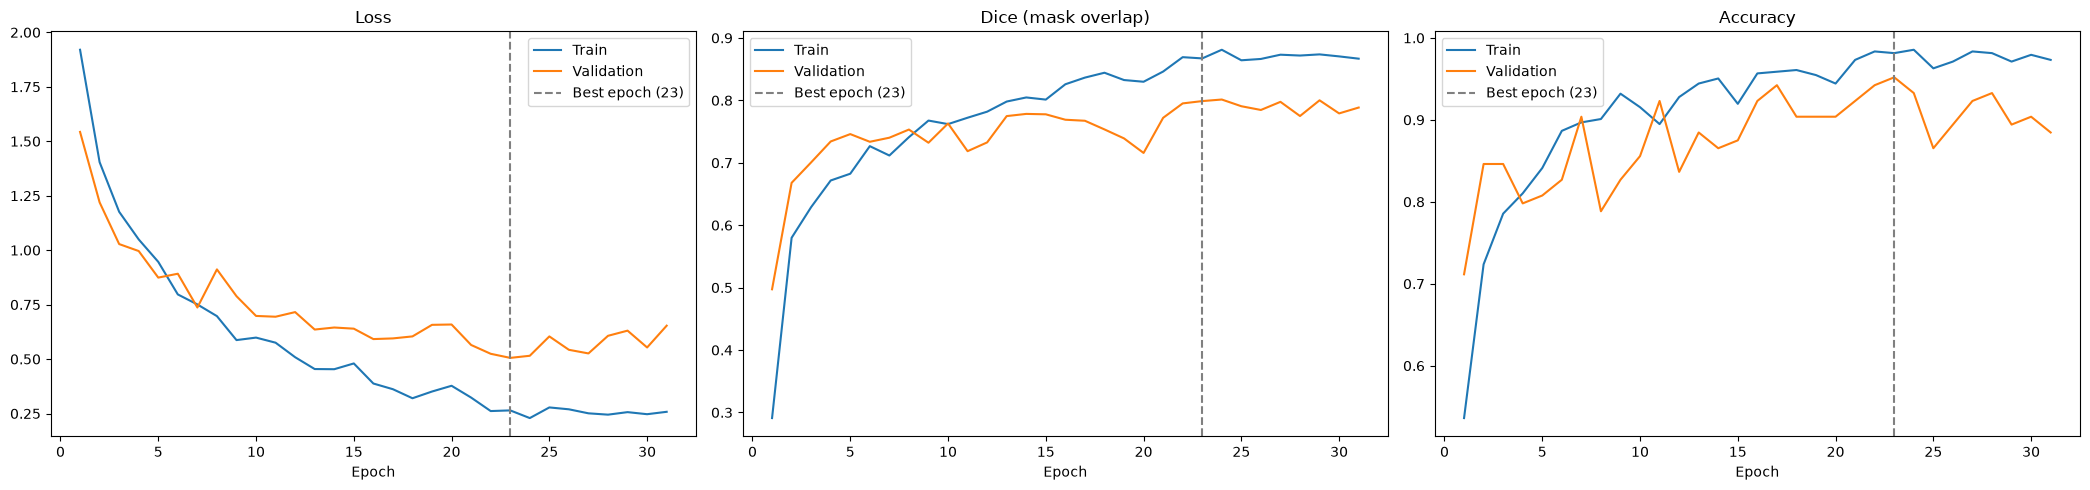

In [13]:
plots = [('loss', 'Loss'), ('dice', 'Dice (mask overlap)')] + ([('acc', 'Accuracy')] if MULTI_TASK else [])
fig, axes = plt.subplots(1, len(plots), figsize=(7 * len(plots), 5))

for ax, (metric, title) in zip(axes, plots):
    ax.plot(history['epoch'], history[f'train_{metric}'], label='Train')
    ax.plot(history['epoch'], history[f'val_{metric}'], label='Validation')
    ax.axvline(best_epoch, color='grey', linestyle='--', label=f'Best epoch ({best_epoch})')
    ax.set_xlabel('Epoch')
    ax.set_title(title)
    ax.legend()

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'training_curves.png', dpi=120, bbox_inches='tight')
plt.show()

## 7. Evaluate on the test set

We reload the **best** saved model and predict every test image. Each predicted mask is:
1. turned into True/False with `MASK_THRESHOLD`,
2. resized back to the **original image size** with `unpad_mask`,
3. compared with the true mask (Dice, IoU),
4. saved to `masks/`, with the same folder and file name as the image, for `04_measure`.

In [14]:
model.load_state_dict(torch.load(OUTPUT_DIR / 'model.pt', map_location=device))
model.eval()

mask_probs, class_probs = [], []
with torch.no_grad():
    for images, _, _ in test_loader:
        mask_logits, class_logits = forward(images.to(device))
        mask_probs.append(torch.sigmoid(mask_logits)[:, 0].cpu())          # lesion probability per pixel
        if MULTI_TASK:
            class_probs.append(torch.softmax(class_logits, dim=1).cpu())   # [P(normal), P(benign), P(malignant)]

mask_probs = torch.cat(mask_probs).numpy()                                  # (test images, 256, 256)
class_probs = torch.cat(class_probs).numpy() if MULTI_TASK else None

In [15]:
rows = []
for i, row in test_df.iterrows():
    pred = unpad_mask(mask_probs[i] > MASK_THRESHOLD, row['width'], row['height'])   # original image size
    truth = np.array(load_mask(row['mask_paths'])) > 127

    mask_path = MASK_DIR / row['image_path']                     # e.g. masks/benign/benign (12).png
    mask_path.parent.mkdir(parents=True, exist_ok=True)
    Image.fromarray(pred.astype(np.uint8) * 255).save(mask_path)

    rows.append({
        'image_path': row['image_path'],
        'label': row['label'],
        'has_markers': row['has_markers'],
        'pred_mask_path': str(mask_path.relative_to(OUTPUT_DIR)),
        'dice': dice_score(pred, truth),
        'iou': iou_score(pred, truth),
        'true_area_px': int(truth.sum()),
        'pred_area_px': int(pred.sum()),
    })

results = pd.DataFrame(rows)

if MULTI_TASK:
    for k, class_name in enumerate(CLASSES):
        results[f'prob_{class_name}'] = class_probs[:, k].round(4)
    results['predicted'] = [CLASSES[k] for k in class_probs.argmax(axis=1)]
    results['correct'] = results['predicted'] == results['label']

results.to_csv(OUTPUT_DIR / 'test_predictions.csv', index=False)
print(f'Saved {len(results)} predicted masks to {MASK_DIR}')
results.head()

Saved 104 predicted masks to outputs/unet_multitask/masks


,image_path,label,has_markers,pred_mask_path,dice,iou,true_area_px,pred_area_px,prob_normal,prob_benign,prob_malignant,predicted,correct
0,normal/normal (103).png,normal,False,masks/normal/normal (103).png,1.0,1.0,0,0,0.9999,0.0001,0.0000,normal,True
1,normal/normal (108).png,normal,True,masks/normal/normal (108).png,0.0,0.0,0,2817,0.2314,0.7475,0.0212,benign,False
2,normal/normal (114).png,normal,True,masks/normal/normal (114).png,1.0,1.0,0,0,0.9959,0.0040,0.0000,normal,True
3,normal/normal (115).png,normal,False,masks/normal/normal (115).png,1.0,1.0,0,0,0.9999,0.0001,0.0000,normal,True
4,normal/normal (120).png,normal,False,masks/normal/normal (120).png,1.0,1.0,0,0,0.9997,0.0003,0.0000,normal,True


### Segmentation results

- **Dice and IoU** are averaged over **tumour images only**. Normal images have no lesion, so overlap isn't meaningful for them.
- For **normal images**, we instead count how often the model draws a lesion that isn't there (a false lesion).

In [16]:
tumour = results['label'] != 'normal'

metrics = {
    'dice_tumour_images': float(results.loc[tumour, 'dice'].mean()),
    'iou_tumour_images': float(results.loc[tumour, 'iou'].mean()),
    'dice_benign': float(results.loc[results['label'] == 'benign', 'dice'].mean()),
    'dice_malignant': float(results.loc[results['label'] == 'malignant', 'dice'].mean()),
    'normal_images_with_false_lesion': float((results.loc[~tumour, 'pred_area_px'] >= MIN_LESION_PIXELS).mean()),
    'tumour_images_with_no_lesion_found': float((results.loc[tumour, 'pred_area_px'] < MIN_LESION_PIXELS).mean()),
    'test_images': int(len(results)),
}

for name, value in metrics.items():
    print(f'{name:36s} {value:.3f}' if isinstance(value, float) else f'{name:36s} {value}')

dice_tumour_images                   0.768
iou_tumour_images                    0.687
dice_benign                          0.779
dice_malignant                       0.745
normal_images_with_false_lesion      0.176
tumour_images_with_no_lesion_found   0.034
test_images                          104


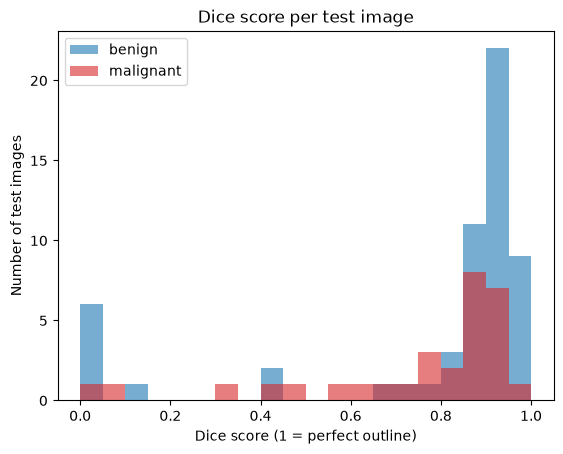

In [17]:
# Dice score of every tumour image, by class
for class_name, color in [('benign', 'tab:blue'), ('malignant', 'tab:red')]:
    plt.hist(results.loc[results['label'] == class_name, 'dice'], bins=20, range=(0, 1),
             alpha=0.6, color=color, label=class_name)
plt.xlabel('Dice score (1 = perfect outline)')
plt.ylabel('Number of test images')
plt.title('Dice score per test image')
plt.legend()
plt.savefig(OUTPUT_DIR / 'dice_distribution.png', dpi=120, bbox_inches='tight')
plt.show()

### Classification results (multi-task only)

The same numbers as `02_model_classifier`, so the two models can be compared directly.

              precision    recall  f1-score   support

      normal      0.778     0.824     0.800        17
      benign      0.828     0.930     0.876        57
   malignant      0.955     0.700     0.808        30

    accuracy                          0.846       104
   macro avg      0.853     0.818     0.828       104
weighted avg      0.856     0.846     0.844       104



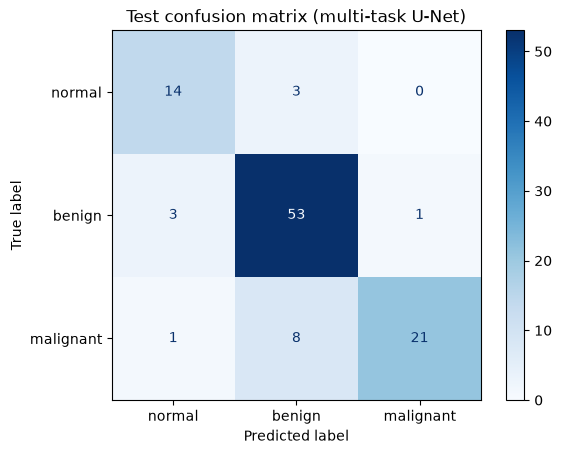

In [18]:
if MULTI_TASK:
    y_true = test_df['target'].values
    y_pred = class_probs.argmax(axis=1)
    print(classification_report(y_true, y_pred, target_names=CLASSES, digits=3))

    is_tumour, p_tumour = y_true != 0, class_probs[:, 1] + class_probs[:, 2]    # P(tumour) = P(benign) + P(malignant)
    is_malignant, p_malignant = y_true == 2, class_probs[:, 2]
    pred_tumour = p_tumour >= 0.5

    metrics.update({
        'accuracy': float((y_pred == y_true).mean()),
        'tumour_sensitivity': float((pred_tumour & is_tumour).sum() / is_tumour.sum()),
        'tumour_specificity': float((~pred_tumour & ~is_tumour).sum() / (~is_tumour).sum()),
        'tumour_roc_auc': float(roc_auc_score(is_tumour, p_tumour)),
        'malignant_recall': float(((y_pred == 2) & is_malignant).sum() / is_malignant.sum()),
        'malignant_precision': float(((y_pred == 2) & is_malignant).sum() / max((y_pred == 2).sum(), 1)),
        'malignant_roc_auc': float(roc_auc_score(is_malignant, p_malignant)),
    })

    ConfusionMatrixDisplay(confusion_matrix(y_true, y_pred), display_labels=CLASSES).plot(cmap='Blues')
    plt.title('Test confusion matrix (multi-task U-Net)')
    plt.savefig(OUTPUT_DIR / 'confusion_matrix.png', dpi=120, bbox_inches='tight')
    plt.show()
else:
    print('MULTI_TASK is False: no classification head, skipping.')

### Shortcut check: images with vs without markers

If results are much better on images with markers, the model may be using the markers instead of the tissue.

In [19]:
marker_check = results[tumour].groupby('has_markers')['dice'].agg(dice='mean', images='count')
metrics['dice_with_markers'] = float(marker_check['dice'].get(True, float('nan')))
metrics['dice_without_markers'] = float(marker_check['dice'].get(False, float('nan')))

if MULTI_TASK:
    accuracy_check = results.groupby('has_markers')['correct'].mean()
    metrics['accuracy_with_markers'] = float(accuracy_check.get(True, float('nan')))
    metrics['accuracy_without_markers'] = float(accuracy_check.get(False, float('nan')))

(OUTPUT_DIR / 'metrics.json').write_text(json.dumps(metrics, indent=2))     # save all test results
marker_check.round(3)

,dice,images
has_markers,,
False,0.842,30
True,0.728,57


## 8. See the predictions

**Green** = true lesion outline, **red** = predicted outline.

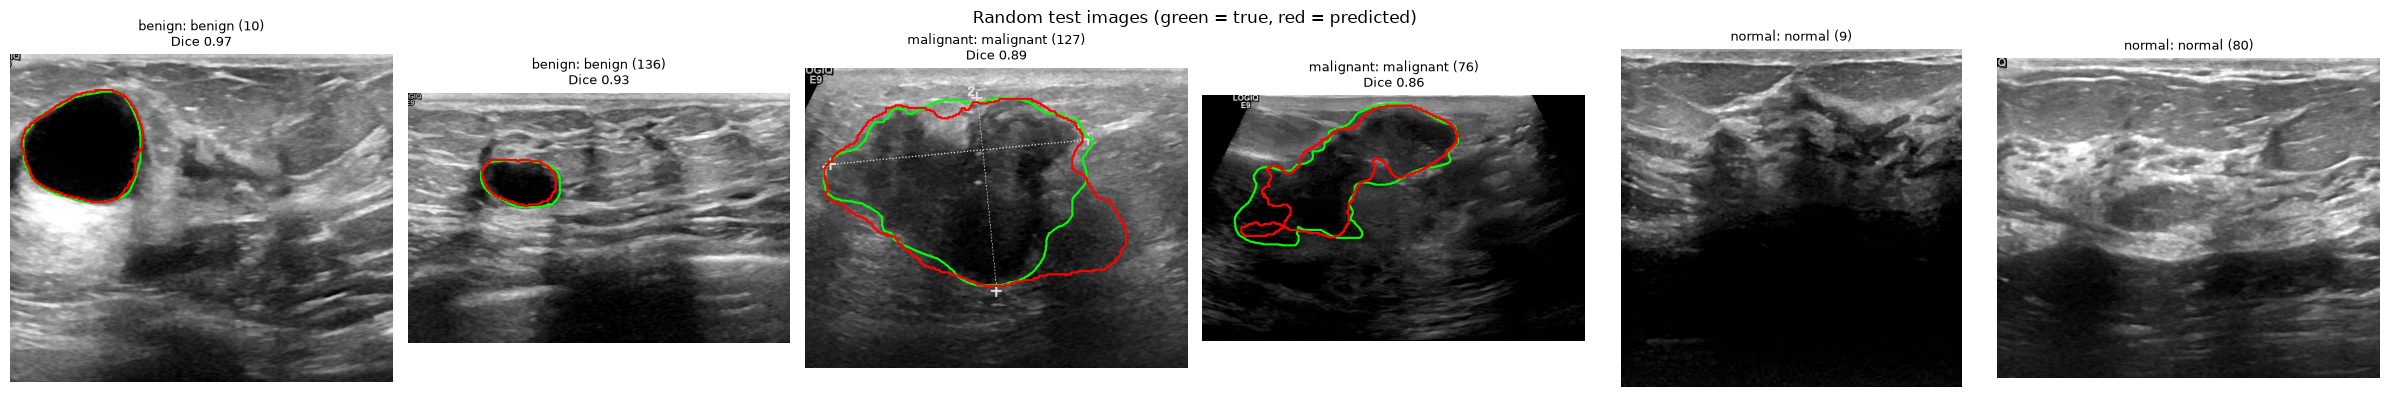

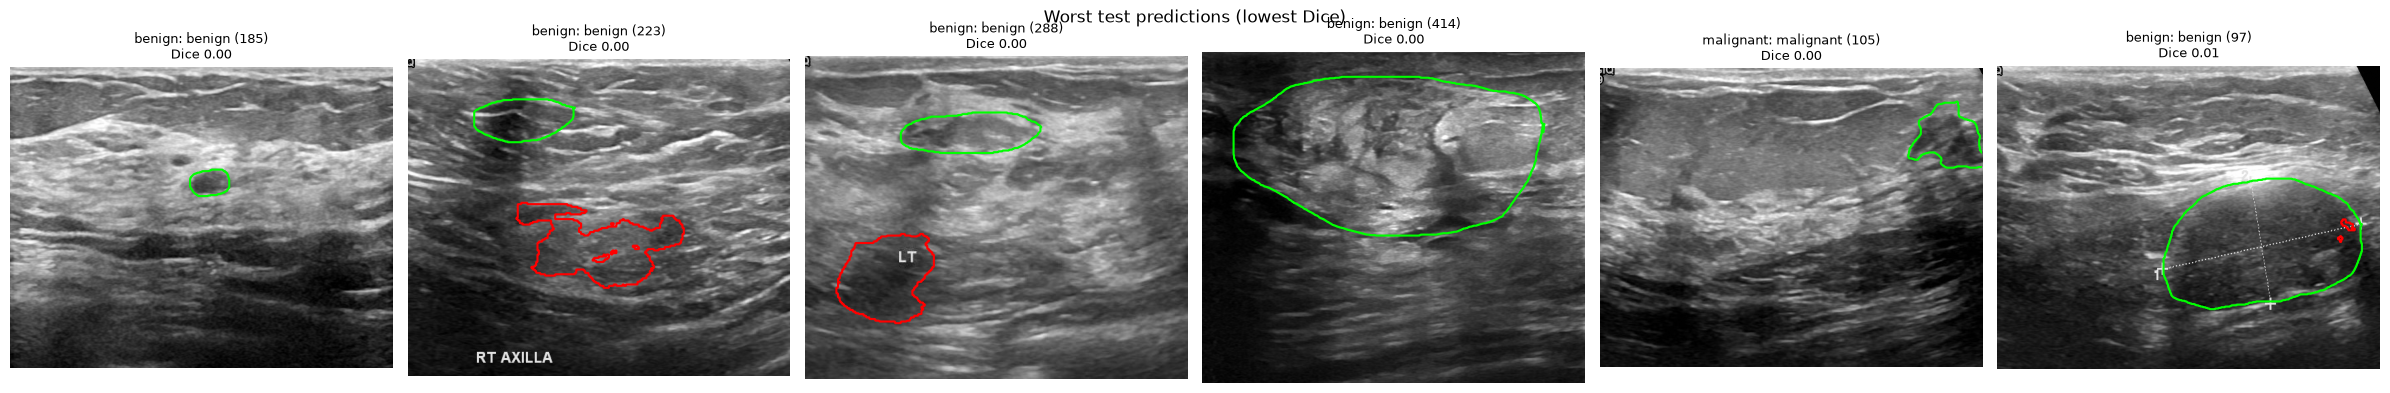

In [20]:
def show_predictions(rows, title, file_name):
    """Show test images with the true (green) and predicted (red) outlines, and save the figure."""
    fig, axes = plt.subplots(1, len(rows), figsize=(4 * len(rows), 4), squeeze=False)
    for ax, row in zip(axes[0], rows.itertuples()):
        image = Image.open(DATA_DIR / row.image_path).convert('L')
        truth = np.array(load_mask(test_df.loc[test_df['image_path'] == row.image_path, 'mask_paths'].iloc[0])) > 127
        pred = np.array(Image.open(OUTPUT_DIR / row.pred_mask_path)) > 127

        ax.imshow(image, cmap='gray')
        if truth.any():
            ax.contour(truth, levels=[0.5], colors='lime', linewidths=1.5)
        if pred.any():
            ax.contour(pred, levels=[0.5], colors='red', linewidths=1.5)

        name = f'{row.label}: {Path(row.image_path).stem}'
        ax.set_title(f'{name}\nDice {row.dice:.2f}' if row.label != 'normal' else name, fontsize=9)
        ax.axis('off')
    fig.suptitle(title)
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / file_name, dpi=120, bbox_inches='tight')
    plt.show()


examples = results.groupby('label', group_keys=False).sample(2, random_state=RANDOM_STATE)   # 2 per class
show_predictions(examples, 'Random test images (green = true, red = predicted)', 'prediction_examples.png')

worst = results[tumour].nsmallest(6, 'dice')                                             # hardest cases
show_predictions(worst, 'Worst test predictions (lowest Dice)', 'worst_predictions.png')

## 9. Save the config

The app needs to rebuild exactly the same model, preprocess uploaded images the same way and use the same threshold. Everything it needs is stored here.

In [21]:
config = {
    'model_name': 'U-Net (multi-task)' if MULTI_TASK else 'U-Net',
    'architecture': 'Unet',
    'encoder': ENCODER,
    'multi_task': MULTI_TASK,
    'classes': CLASSES,
    'image_size': IMAGE_SIZE,
    'preprocessing': 'grayscale -> pad to square with black -> resize -> 3 channels -> ImageNet normalisation',
    'normalize_mean': IMAGENET_MEAN,
    'normalize_std': IMAGENET_STD,
    'mask_threshold': MASK_THRESHOLD,
    'min_lesion_pixels': MIN_LESION_PIXELS,
    'classification_dropout': 0.2,
    'class_loss_weight': CLASS_LOSS_WEIGHT,
    'best_epoch': int(best_epoch),
    'epochs_trained': int(len(history)),
    'batch_size': BATCH_SIZE,
    'learning_rate': LEARNING_RATE,
    'images': {'train': len(train_df), 'val': len(val_df), 'test': len(test_df)},
    'trained_on': datetime.now().strftime('%Y-%m-%d %H:%M'),
}

(OUTPUT_DIR / 'config.json').write_text(json.dumps(config, indent=2))
print('Saved files:')
for path in sorted(OUTPUT_DIR.iterdir()):
    size = sum(f.stat().st_size for f in path.rglob('*')) if path.is_dir() else path.stat().st_size
    print(f'  {path.name:24s} {size / 1024:10.1f} KB')

Saved files:
  config.json                     0.7 KB
  confusion_matrix.png           24.3 KB
  dice_distribution.png          20.9 KB
  history.csv                     3.6 KB
  masks                          92.3 KB
  metrics.json                    0.8 KB
  model.pt                    95612.5 KB
  prediction_examples.png       732.7 KB
  test_predictions.csv           14.5 KB
  training_curves.png           128.0 KB
  worst_predictions.png         803.0 KB


## 10. Check: reload and predict, the way the app will

This rebuilds the model from the saved files alone and predicts one test image. Its mask should match the one saved in `masks/` (Dice close to 1). If it works here, the app can use the same two functions.

In [22]:
def load_unet(folder):
    """Rebuild the trained U-Net from model.pt and config.json."""
    config = json.loads((folder / 'config.json').read_text())
    head = {'classes': len(config['classes']), 'dropout': config['classification_dropout']} if config['multi_task'] else None
    net = smp.Unet(encoder_name=config['encoder'], encoder_weights=None, in_channels=3, classes=1, aux_params=head)
    net.load_state_dict(torch.load(folder / 'model.pt', map_location='cpu'))
    net.eval()
    return net, config


def predict(net, config, image):
    """For one PIL image: lesion mask at the original size, plus class probabilities if multi-task."""
    size = config['image_size']
    width, height = image.size
    padded = ImageOps.pad(image.convert('L'), (size, size), method=Image.BICUBIC, color=0)

    x = torch.from_numpy(np.array(padded)).float().div(255).unsqueeze(0).repeat(3, 1, 1)
    x = (x - torch.tensor(config['normalize_mean']).view(3, 1, 1)) / torch.tensor(config['normalize_std']).view(3, 1, 1)

    with torch.no_grad():
        output = net(x.unsqueeze(0))
    mask_logits, class_logits = output if config['multi_task'] else (output, None)

    mask = unpad_mask(torch.sigmoid(mask_logits)[0, 0].numpy() > config['mask_threshold'], width, height, size)
    probabilities = None
    if class_logits is not None:
        probabilities = dict(zip(config['classes'], torch.softmax(class_logits, dim=1)[0].numpy().round(4).tolist()))
    return mask, probabilities


net, saved_config = load_unet(OUTPUT_DIR)
sample = results[tumour].iloc[0]
mask, probabilities = predict(net, saved_config, Image.open(DATA_DIR / sample['image_path']))
saved_mask = np.array(Image.open(OUTPUT_DIR / sample['pred_mask_path'])) > 127

print('Image:          ', sample['image_path'])
print('True label:     ', sample['label'])
print('Probabilities:  ', probabilities)
print(f'Lesion pixels:   {mask.sum()}')
print(f'Match with saved mask (Dice): {dice_score(mask, saved_mask):.3f}  (should be close to 1)')

Image:           benign/benign (10).png
True label:      benign
Probabilities:   {'normal': 0.0, 'benign': 1.0, 'malignant': 0.0}
Lesion pixels:   32774
Match with saved mask (Dice): 1.000  (should be close to 1)
